In [1]:
import numpy as np

def simulate_hull_white(r0, a, sigma, theta_func, T, n_steps, n_paths):
    """
    Simulation Monte Carlo du modèle Hull-White à 1 facteur.
    
    Parameters:
    - r0: Taux instantané initial
    - a: Vitesse de retour à la moyenne
    - sigma: Volatilité du taux court
    - theta_func: Fonction du temps assurant l'ajustement à la courbe initiale
    - T: Horizon temporel (années)
    - n_steps: Nombre de pas de temps
    - n_paths: Nombre de trajectoires simulées
    """
    dt = T / n_steps
    times = np.linspace(0, T, n_steps + 1)
    rates = np.zeros((n_steps + 1, n_paths))
    rates[0] = r0

    for i in range(n_steps):
        t = times[i]
        # Generation de variables normales N(0, 1)
        Z = np.random.normal(0, 1, size=n_paths)
        
        # Discrétisation d'Euler
        drift = (theta_func(t) - a * rates[i]) * dt
        diffusion = sigma * np.sqrt(dt) * Z
        
        rates[i + 1] = rates[i] + drift + diffusion

    return times, rates

# Exemple d'utilisation
r0 = 0.03          # Taux initial à 3%
a = 0.1            # Vitesse de réversion
sigma = 0.015      # Volatilité à 1.5%
theta = lambda t: 0.1 * 0.03 + 0.001 * t  # Simplification déterministe de theta(t)

times, hw_paths = simulate_hull_white(r0, a, sigma, theta, T=5, n_steps=250, n_paths=1000)
print("Forme de la matrice HW (Pas de temps, Trajectoires):", hw_paths.shape)

Forme de la matrice HW (Pas de temps, Trajectoires): (251, 1000)


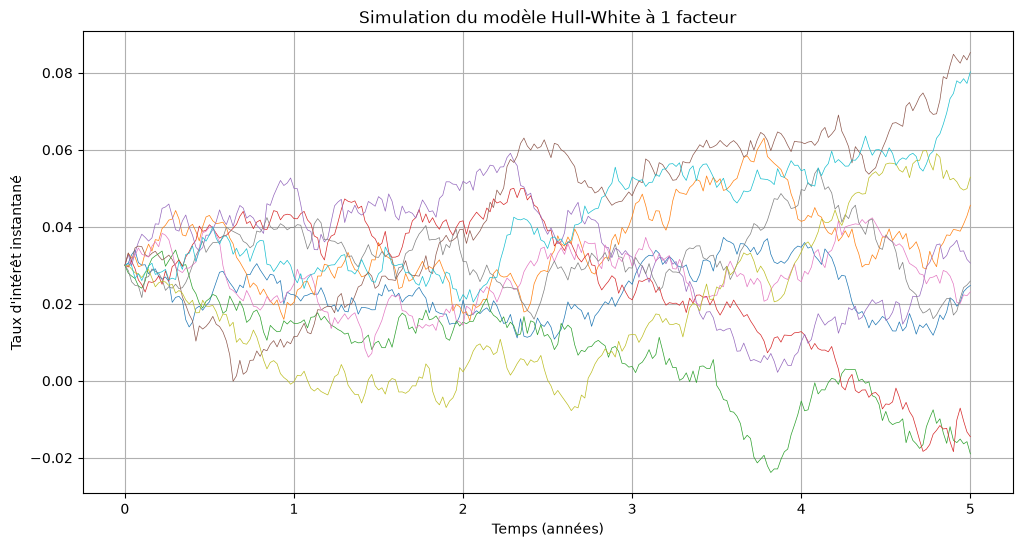

In [3]:
### représentation graphique des trajectoires simulées
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
for i in range(min(10, hw_paths.shape[1])):  # Afficher seulement les 10 premières trajectoires
    plt.plot(times, hw_paths[:, i], lw=0.5)
plt.title("Simulation du modèle Hull-White à 1 facteur")
plt.xlabel("Temps (années)")
plt.ylabel("Taux d'intérêt instantané")
plt.grid()
plt.show()

